<a href="https://colab.research.google.com/github/Rageel-28/PCVK_Ganjil_2026/blob/main/Week6_19.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 6 – Filter Spasial (Low Pass, High Pass, Point / Line / Edge Detection)
**Mata Kuliah:** PCVK  |  **Kelas:** TI-3C  |  **NIM:** 244107020136  |  **Nama:** Rakagali Resda Krisandi Putra

Notebook ini berisi seluruh kode Modul 6 secara berurutan: sel identitas, fungsi konvolusi manual (tanpa fungsi konvolusi OpenCV), filter dasar, Percobaan 1–7 (filter library dan filter modern), serta Tugas Praktikum 1–3.

## 1. Persiapan Notebook
### Langkah 1 – Sel identitas

In [1]:
import sys, platform, hashlib, datetime, zoneinfo

NAMA = 'Rakagali Resda Krisandi Putra'
NIM  = '244107020136'

waktu = datetime.datetime.now(zoneinfo.ZoneInfo('Asia/Jakarta'))
print('NAMA   :', NAMA)
print('NIM    :', NIM)
print('WAKTU  :', waktu.strftime('%Y-%m-%d %H:%M:%S %Z'))
print('SISTEM :', sys.version.split()[0], platform.platform())
kunci = NIM + '|' + waktu.strftime('%Y-%m-%d')
print('TOKEN  :', hashlib.sha256(kunci.encode()).hexdigest()[:16])

NAMA   : Rakagali Resda Krisandi Putra
NIM    : 244107020136
WAKTU  : 2026-10-09 08:09:32 WIB
SISTEM : 3.13.16 Linux-6.6.122+-x86_64-with-glibc2.39
TOKEN  : e6466e3316cde210


### Langkah 2 – Mount Google Drive dan import library

In [2]:
# Di Google Colab: mount Drive. Di luar Colab sel ini dilewati (gambar cadangan dipakai, lihat Langkah 3).
try:
    from google.colab import drive
    drive.mount('/content/drive')
    DI_COLAB = True
except Exception:
    DI_COLAB = False
print('Berjalan di Colab:', DI_COLAB)

Mounted at /content/drive
Berjalan di Colab: True


In [3]:
import os, math, time
import numpy as np
import matplotlib.pyplot as plt
import cv2 as cv

HASIL = {}
print('OpenCV', cv.__version__, '| NumPy', np.__version__)

OpenCV 5.0.0 | NumPy 2.1.3


### Langkah 3 – Folder gambar dan fungsi pemuat gambar

In [4]:
FOLDER = '/content/drive/MyDrive/PCVK/Images'
def muat(nama):

    path = os.path.join(FOLDER, nama)
    img = cv.imread(path)
    if img is not None:
        print('OK   ', path, img.shape)
        return img
    from skimage import data
    cadangan = {'mandrill.tiff': data.astronaut(), 'lena.jpg': data.astronaut(),
                'djawatan.jpg': data.coffee()}
    rgb = cadangan[nama]
    print('CADANGAN untuk', nama, '->', rgb.shape, '(berkas asli tidak ditemukan)')
    return cv.cvtColor(rgb, cv.COLOR_RGB2BGR)

def tampil(daftar_citra, judul, ukuran=(15, 5)):
    """Tampilkan beberapa citra berdampingan (grayscale atau berwarna)."""
    plt.figure(figsize=ukuran)
    for i, (im, t) in enumerate(zip(daftar_citra, judul), 1):
        plt.subplot(1, len(daftar_citra), i)
        if im.ndim == 2:
            plt.imshow(im, cmap='gray', vmin=0, vmax=255)
        else:
            plt.imshow(cv.cvtColor(im, cv.COLOR_BGR2RGB))
        plt.title(t, fontsize=10)
        plt.axis('off')
    plt.tight_layout()
    plt.show()

def u8(x):
    """Potong ke rentang 0-255 lalu ubah ke uint8 untuk ditampilkan."""
    return np.clip(x, 0, 255).astype(np.uint8)

mandrill = muat('mandrill.tiff')
lena     = muat('lena.jpg')
djawatan = muat('djawatan.jpg')
mandrill_gray = cv.cvtColor(mandrill, cv.COLOR_BGR2GRAY)
lena_gray     = cv.cvtColor(lena, cv.COLOR_BGR2GRAY)

OK    /content/drive/MyDrive/PCVK/Images/mandrill.tiff (512, 512, 3)
OK    /content/drive/MyDrive/PCVK/Images/lena.jpg (512, 512, 3)
CADANGAN untuk djawatan.jpg -> (400, 600, 3) (berkas asli tidak ditemukan)


## 2. Praktikum Filter Spasial
### Langkah 4 – Fungsi konvolusi tanpa library

In [5]:
def convolution2d(image, kernel, stride=1, padding=0):
    """Konvolusi 2D manual (algoritma Bagian C, tanpa cv.filter2D / scipy).
    z(x,y) = jumlah H(k1,k2) * Img(x+k1, y+k2), kernel digeser per 'stride' piksel.
    padding: jumlah piksel bernilai 0 yang ditambahkan di keempat sisi citra."""
    image  = np.asarray(image, dtype=np.float64)
    kernel = np.asarray(kernel, dtype=np.float64)
    kh, kw = kernel.shape
    if padding > 0:
        image = np.pad(image, padding, mode='constant', constant_values=0)
    H, W = image.shape
    out_h = (H - kh) // stride + 1
    out_w = (W - kw) // stride + 1
    out = np.zeros((out_h, out_w), dtype=np.float64)
    # perulangan atas posisi kernel (k1, k2); tiap iterasi memproses semua piksel sekaligus
    for k1 in range(kh):
        for k2 in range(kw):
            irisan = image[k1:k1 + (out_h - 1) * stride + 1:stride,
                           k2:k2 + (out_w - 1) * stride + 1:stride]
            out += kernel[k1, k2] * irisan
    return out

def convolution2d_loop(image, kernel):
    """Versi perulangan murni per piksel (persis pseudocode modul) untuk verifikasi."""
    kh, kw = kernel.shape
    out_h, out_w = image.shape[0] - kh + 1, image.shape[1] - kw + 1
    out = np.zeros((out_h, out_w))
    for x in range(out_h):
        for y in range(out_w):
            for k1 in range(kh):
                for k2 in range(kw):
                    out[x, y] += kernel[k1, k2] * image[x + k1, y + k2]
    return out
print('Fungsi konvolusi siap.')

Fungsi konvolusi siap.


### Langkah 5 – Verifikasi dengan contoh matriks 5×5 pada modul

In [6]:
f = np.array([[4, 4, 3, 5, 4],
              [6, 6, 5, 5, 2],
              [5, 6, 6, 6, 2],
              [6, 7, 5, 5, 3],
              [3, 5, 2, 4, 4]], dtype=np.float64)
g = np.array([[ 0, -1,  0],
              [-1,  4, -1],
              [ 0, -1,  0]], dtype=np.float64)

hasil_vektor = convolution2d(f, g)          # tanpa padding -> 3x3 (piksel pinggir diabaikan)
hasil_loop   = convolution2d_loop(f, g)
print('Hasil convolution2d:'); print(hasil_vektor)
print('Hasil perulangan murni:'); print(hasil_loop)
print('Sama persis?', np.array_equal(hasil_vektor, hasil_loop))
print('Pembanding cv.filter2D (hanya untuk cek):')
print(cv.filter2D(f, cv.CV_64F, g, borderType=cv.BORDER_CONSTANT)[1:4, 1:4])
HASIL['contoh5x5'] = hasil_vektor.tolist()

Hasil convolution2d:
[[3. 0. 2.]
 [0. 2. 6.]
 [6. 0. 2.]]
Hasil perulangan murni:
[[3. 0. 2.]
 [0. 2. 6.]
 [6. 0. 2.]]
Sama persis? True
Pembanding cv.filter2D (hanya untuk cek):
[[3. 0. 2.]
 [0. 2. 6.]
 [6. 0. 2.]]


### Langkah 6 – Verifikasi pada citra nyata: bandingkan dengan `cv.filter2D`

Ukuran citra masukan : (512, 512)
Ukuran hasil manual  : (512, 512)
Selisih maksimum manual vs cv.filter2D : 0.0


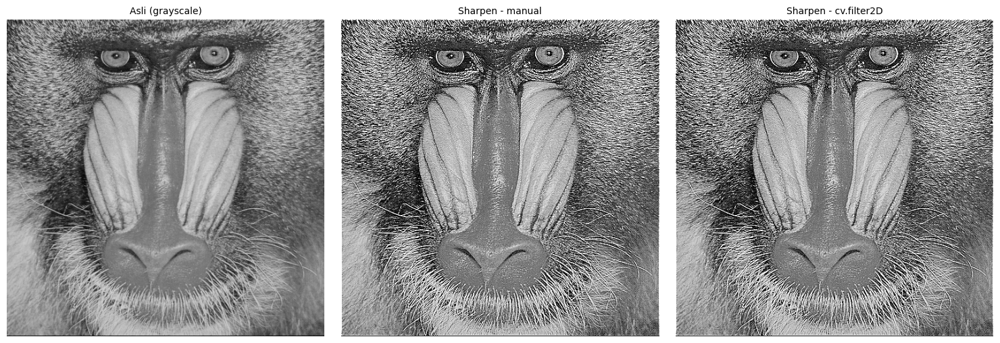

In [7]:
kernel_sharpen = np.array([[ 0, -1,  0],
                           [-1,  5, -1],
                           [ 0, -1,  0]])

# padding = 1 pada kernel 3x3 membuat ukuran keluaran sama dengan citra masukan
manual = convolution2d(mandrill_gray, kernel_sharpen, stride=1, padding=1)
pustaka = cv.filter2D(mandrill_gray.astype(np.float64), cv.CV_64F, kernel_sharpen,
                      borderType=cv.BORDER_CONSTANT)
selisih = np.abs(manual - pustaka).max()
print('Ukuran citra masukan :', mandrill_gray.shape)
print('Ukuran hasil manual  :', manual.shape)
print('Selisih maksimum manual vs cv.filter2D :', selisih)
HASIL['selisih_filter2d'] = float(selisih)

tampil([mandrill_gray, u8(manual), u8(pustaka)],
       ['Asli (grayscale)', 'Sharpen - manual', 'Sharpen - cv.filter2D'])

### Langkah 7 – Pengaruh stride dan padding

In [8]:
k_avg = np.ones((3, 3)) / 9
contoh = [('stride 1, padding 0', 1, 0), ('stride 1, padding 1', 1, 1), ('stride 2, padding 1', 2, 1)]
for nama, s, p in contoh:
    h = convolution2d(mandrill_gray, k_avg, stride=s, padding=p)
    print('%-22s -> ukuran keluaran %s' % (nama, h.shape))
    HASIL['ukuran_' + nama] = list(h.shape)

stride 1, padding 0    -> ukuran keluaran (510, 510)
stride 1, padding 1    -> ukuran keluaran (512, 512)
stride 2, padding 1    -> ukuran keluaran (256, 256)


### Langkah 8 – Filter dasar: Average, Low Pass, High Pass

Jumlah koefisien -> average: 1.00 | low pass: 1.00 | high pass: 0.00


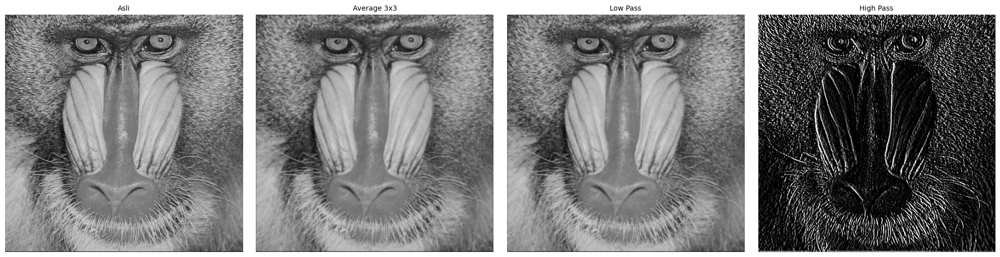

asli       rerata  129.62 | std   42.31
average    rerata  129.37 | std   36.88
low pass   rerata  129.43 | std   37.55
high pass  rerata    0.31 | std  129.11


In [9]:
kernel_avg  = np.ones((3, 3)) / 9
kernel_lpf  = np.array([[1, 1, 1],
                        [1, 4, 1],
                        [1, 1, 1]]) / 12
kernel_hpf  = np.array([[-1, 0, 1],
                        [-1, 0, 3],
                        [-3, 0, 1]])
print('Jumlah koefisien -> average: %.2f | low pass: %.2f | high pass: %.2f'
      % (kernel_avg.sum(), kernel_lpf.sum(), kernel_hpf.sum()))

avg = convolution2d(mandrill_gray, kernel_avg, 1, 1)
lpf = convolution2d(mandrill_gray, kernel_lpf, 1, 1)
hpf = convolution2d(mandrill_gray, kernel_hpf, 1, 1)
tampil([mandrill_gray, u8(avg), u8(lpf), u8(hpf)],
       ['Asli', 'Average 3x3', 'Low Pass', 'High Pass'], (20, 5))
for nama, h in [('asli', mandrill_gray), ('average', avg), ('low pass', lpf), ('high pass', hpf)]:
    print('%-10s rerata %7.2f | std %7.2f' % (nama, h.mean(), h.std()))
    HASIL['dasar_' + nama] = [float(h.mean()), float(h.std())]

### Langkah 9 – Filter pada tabel praktikum: Sharpen, Emboss, Left Sobel, Canny kernel, Gaussian 21×21

Kernel Gaussian 21x21: jumlah = 1.0 | sigma = 4.583


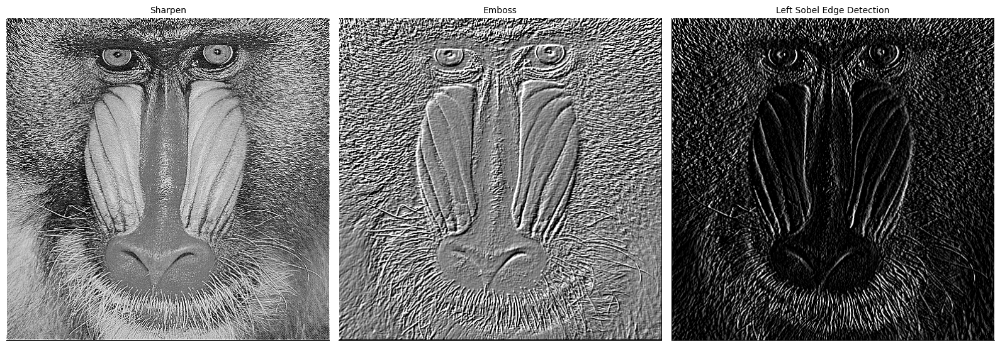

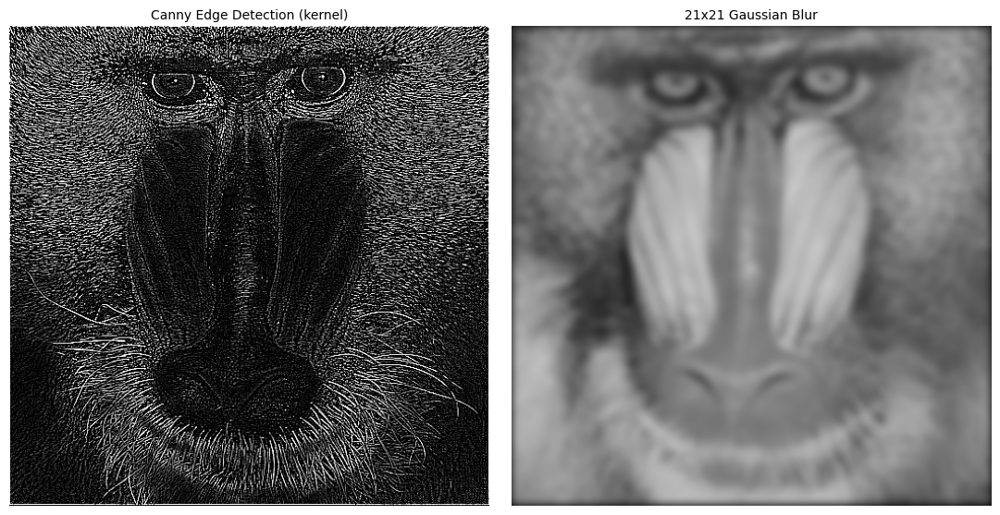

Sharpen                          ukuran (512, 512) | min   -309.0 | maks    623.0
Emboss                           ukuran (512, 512) | min   -515.0 | maks    878.0
Left Sobel Edge Detection        ukuran (512, 512) | min   -767.0 | maks    687.0
Canny Edge Detection (kernel)    ukuran (512, 512) | min   -818.0 | maks   1005.0
21x21 Gaussian Blur              ukuran (512, 512) | min     21.8 | maks    198.7


In [10]:
kernel_emboss = np.array([[-2, -1, 0],
                          [-1,  1, 1],
                          [ 0,  1, 2]])
kernel_sobel_kiri = np.array([[1, 0, -1],
                              [2, 0, -2],
                              [1, 0, -1]])
kernel_canny = np.array([[-1, -1, -1],
                         [-1,  8, -1],
                         [-1, -1, -1]])

kernel_size = 21
sigma = math.sqrt(kernel_size)
gaussian_kernel = cv.getGaussianKernel(kernel_size, sigma)
gauss_kernel = gaussian_kernel @ gaussian_kernel.transpose()
print('Kernel Gaussian 21x21: jumlah =', round(gauss_kernel.sum(), 6), '| sigma =', round(sigma, 3))

sharpen = convolution2d(mandrill_gray, kernel_sharpen, 1, 1)
# jumlah koefisien kernel emboss = 1, jadi hasilnya masih memuat citra asli; kurangi citra asli
# (setara kernel dengan pusat 0, jumlah = 0) lalu +128 agar area datar tampak abu-abu
emboss  = convolution2d(mandrill_gray, kernel_emboss, 1, 1) - mandrill_gray + 128
sobel_k = convolution2d(mandrill_gray, kernel_sobel_kiri, 1, 1)
canny_k = convolution2d(mandrill_gray, kernel_canny, 1, 1)
gauss21 = convolution2d(mandrill_gray, gauss_kernel, 1, kernel_size // 2)

hasil = [sharpen, emboss, sobel_k, canny_k, gauss21]
nama  = ['Sharpen', 'Emboss', 'Left Sobel Edge Detection', 'Canny Edge Detection (kernel)', '21x21 Gaussian Blur']
tampil([u8(h) for h in hasil[:3]], nama[:3], (16, 5.5))
tampil([u8(h) for h in hasil[3:]], nama[3:], (11, 5.5))
for n, h in zip(nama, hasil):
    print('%-32s ukuran %s | min %8.1f | maks %8.1f' % (n, h.shape, h.min(), h.max()))
    HASIL['tabel_' + n] = [float(h.min()), float(h.max()), float(h.std())]

### Langkah 10 – Point detection, line detection, dan edge detection (Roberts, Prewitt, Sobel)

Point detection: respons maksimum = 870.0 | jumlah titik terdeteksi (>=90% maks) = 4


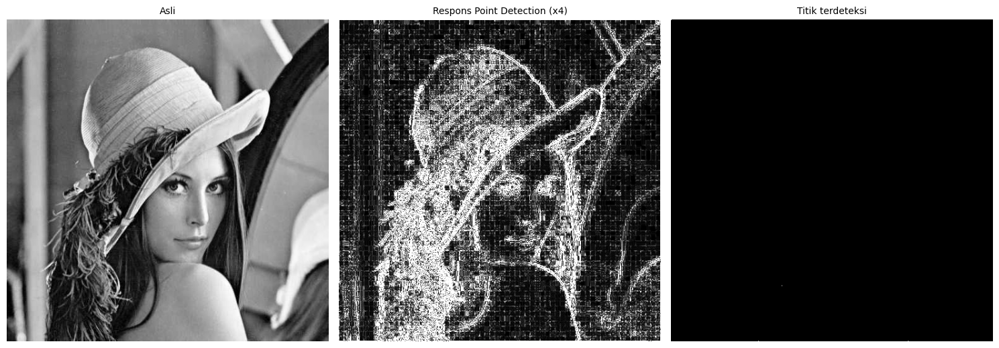

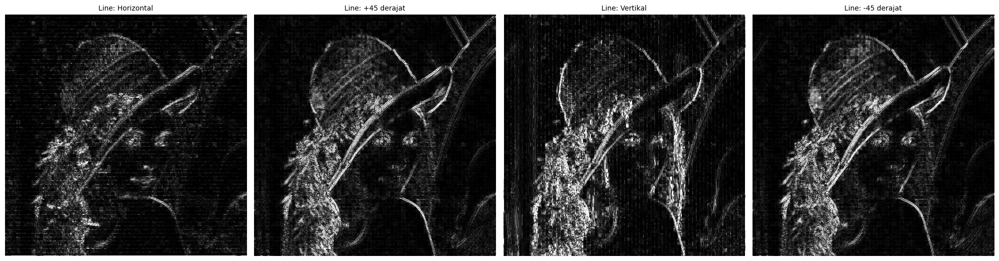

Line Horizontal   respons rata-rata 13.01
Line +45 derajat  respons rata-rata 15.33
Line Vertikal     respons rata-rata 20.53
Line -45 derajat  respons rata-rata 15.76


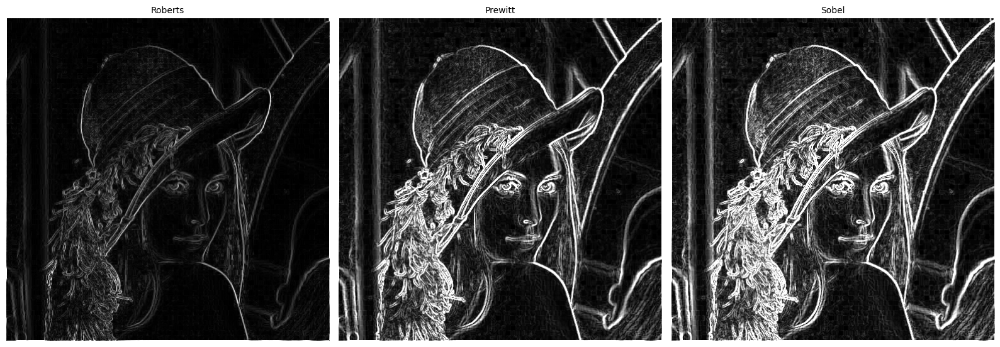

Roberts  respons rata-rata 18.87 | maks 494.0
Prewitt  respons rata-rata 60.19 | maks 872.0
Sobel    respons rata-rata 82.05 | maks 1240.0


In [11]:
k_point = np.array([[1, 1, 1], [1, -8, 1], [1, 1, 1]])
k_line = {'Horizontal': np.array([[-1, -1, -1], [ 2,  2,  2], [-1, -1, -1]]),
          '+45 derajat': np.array([[ 2, -1, -1], [-1,  2, -1], [-1, -1,  2]]),
          'Vertikal':   np.array([[-1,  2, -1], [-1,  2, -1], [-1,  2, -1]]),
          '-45 derajat': np.array([[-1, -1,  2], [-1,  2, -1], [ 2, -1, -1]])}
prewitt_x = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]]); prewitt_y = prewitt_x.T
sobel_x   = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]]); sobel_y   = sobel_x.T
roberts_x = np.array([[-1, 0], [0, 1]]);                    roberts_y = np.array([[0, -1], [1, 0]])

def besar_gradien(kx, ky, citra):
    gx = convolution2d(citra, kx, 1, kx.shape[0] // 2)
    gy = convolution2d(citra, ky, 1, kx.shape[0] // 2)
    n = min(gx.shape[0], gy.shape[0]); m = min(gx.shape[1], gy.shape[1])
    return np.abs(gx[:n, :m]) + np.abs(gy[:n, :m])      # |gx| + |gy| seperti Gambar 10.16

pt = np.abs(convolution2d(lena_gray, k_point, 1, 1))
# ambang titik: 90% dari respons maksimum
titik = (pt >= 0.9 * pt.max()).astype(np.uint8) * 255
print('Point detection: respons maksimum = %.1f | jumlah titik terdeteksi (>=90%% maks) = %d'
      % (pt.max(), (titik > 0).sum()))
HASIL['titik'] = int((titik > 0).sum())

tampil([lena_gray, u8(pt * 4), titik], ['Asli', 'Respons Point Detection (x4)', 'Titik terdeteksi'], (15, 5.5))

garis = [np.abs(convolution2d(lena_gray, k, 1, 1)) for k in k_line.values()]
tampil([u8(g * 2) for g in garis], ['Line: ' + n for n in k_line], (20, 5.5))
for n, g in zip(k_line, garis):
    print('Line %-12s respons rata-rata %.2f' % (n, g.mean()))
    HASIL['line_' + n] = float(g.mean())

tepi = [('Roberts', besar_gradien(roberts_x, roberts_y, lena_gray)),
        ('Prewitt', besar_gradien(prewitt_x, prewitt_y, lena_gray)),
        ('Sobel',   besar_gradien(sobel_x, sobel_y, lena_gray))]
tampil([u8(t) for _, t in tepi], [n for n, _ in tepi], (16, 5.5))
for n, t in tepi:
    print('%-8s respons rata-rata %.2f | maks %.1f' % (n, t.mean(), t.max()))
    HASIL['tepi_' + n] = [float(t.mean()), float(t.max())]

## 3. Filter Library dan Filter Modern
### Percobaan 1 – Gaussian, Sharpen, dan Canny dengan `cv.filter2D`

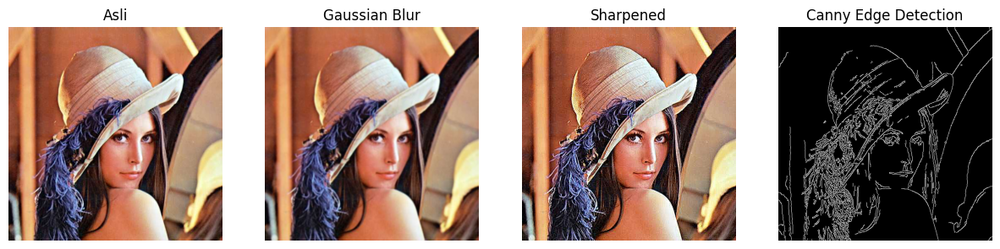

In [12]:
def show_side_by_side(images, titles, figsize=(15, 5)):
    plt.figure(figsize=figsize)
    for i, (img, title) in enumerate(zip(images, titles)):
        if len(img.shape) == 2:      # grayscale
            plt.subplot(1, len(images), i + 1)
            plt.imshow(img, cmap='gray')
        else:                        # color
            plt.subplot(1, len(images), i + 1)
            plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
        plt.title(title)
        plt.axis('off')
    plt.show()

img = lena.copy()
blur = cv.GaussianBlur(img, (7, 7), 1)
edges = cv.Canny(cv.cvtColor(img, cv.COLOR_BGR2GRAY), 100, 200)
sharpen_kernel = np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]])
sharpened = cv.filter2D(img, -1, sharpen_kernel)
show_side_by_side([img, blur, sharpened, edges],
                  ['Asli', 'Gaussian Blur', 'Sharpened', 'Canny Edge Detection'])

### Percobaan 2 – Filter modern: Bilateral Filter dan Edge Preserving / Guided Filter

cv.ximgproc.guidedFilter tidak tersedia (opencv-contrib belum terpasang): Guided Filter dilewati.


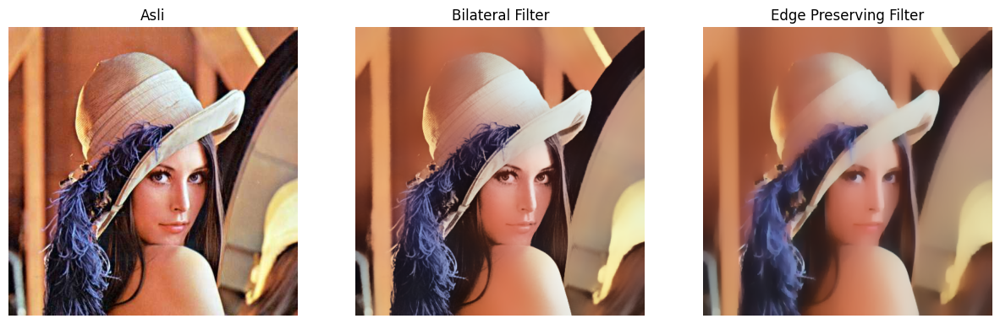

Asli                       rerata |Laplacian| = 11.261
Bilateral Filter           rerata |Laplacian| = 7.390
Edge Preserving Filter     rerata |Laplacian| = 3.232


In [13]:
# Bilateral Filter (edge-preserving)
bilateral = cv.bilateralFilter(img, 50, 100, 100)

# Edge Preserving Filter (alternatif Guided Filter)
edge_preserve = cv.edgePreservingFilter(img, flags=1, sigma_s=100, sigma_r=0.9)

daftar, judul = [img, bilateral, edge_preserve], ['Asli', 'Bilateral Filter', 'Edge Preserving Filter']

# Guided Filter sungguhan (butuh opencv-contrib; dilewati jika tidak tersedia)
if hasattr(cv, 'ximgproc') and hasattr(cv.ximgproc, 'guidedFilter'):
    guided = cv.ximgproc.guidedFilter(guide=img, src=img, radius=8, eps=(0.05 * 255) ** 2)
    daftar.append(guided); judul.append('Guided Filter (ximgproc)')
else:
    print('cv.ximgproc.guidedFilter tidak tersedia (opencv-contrib belum terpasang): Guided Filter dilewati.')
show_side_by_side(daftar, judul, (5 * len(daftar), 5))

# ukuran kehalusan: std gradien (makin kecil = makin halus); tepi: rerata |Laplacian|
def kehalusan(c):
    g = cv.cvtColor(c, cv.COLOR_BGR2GRAY)
    return float(np.abs(cv.Laplacian(g, cv.CV_64F)).mean())
for j, d in zip(judul, daftar):
    print('%-26s rerata |Laplacian| = %.3f' % (j, kehalusan(d)))
    HASIL['p2_' + j] = kehalusan(d)

### Percobaan 3 – Feature map pada CNN (satu lapis konvolusi)

Backend: PyTorch | bobot conv1 (filter 1):
[[-0.267 -0.153  0.12 ]
 [-0.12   0.274  0.101]
 [ 0.1    0.12   0.241]]


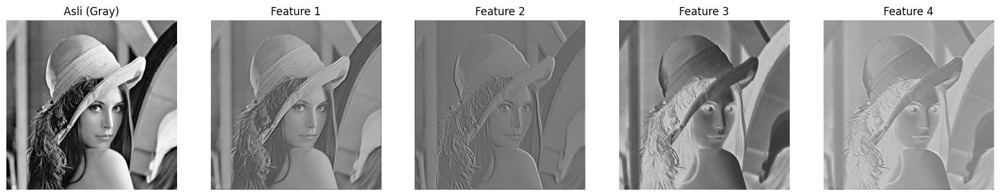

std tiap feature map: [0.112 0.05  0.096 0.109]


In [14]:
# Filter feature map pada CNN: jalankan sel ini beberapa kali dan amati hasilnya.
# Bobot Conv2d diinisialisasi acak, sehingga tiap running memberi feature map berbeda.
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
try:
    import torch, torch.nn as nn

    class SimpleCNN(nn.Module):
        def __init__(self):
            super(SimpleCNN, self).__init__()
            self.conv1 = nn.Conv2d(1, 4, kernel_size=3, stride=1, padding=1)
        def forward(self, x):
            return self.conv1(x)

    model = SimpleCNN()
    img_tensor = torch.tensor(img_gray, dtype=torch.float32).unsqueeze(0).unsqueeze(0) / 255.0
    with torch.no_grad():
        features = model(img_tensor)
    feature_maps = [features[0, i].numpy() for i in range(features.shape[1])]
    print('Backend: PyTorch | bobot conv1 (filter 1):'); print(model.conv1.weight[0, 0].detach().numpy().round(3))
except ImportError:
    # cadangan tanpa PyTorch: kernel 3x3 acak (distribusi seragam seperti inisialisasi Conv2d)
    rng = np.random.default_rng()
    bobot = rng.uniform(-1 / 3, 1 / 3, size=(4, 3, 3))
    feature_maps = [convolution2d(img_gray / 255.0, w, 1, 1) + rng.uniform(-1 / 3, 1 / 3) for w in bobot]
    print('Backend: NumPy (PyTorch tidak terpasang) | bobot filter 1:'); print(bobot[0].round(3))

def norm(m):                      # skala ke 0-255 supaya terlihat
    return u8(255 * (m - m.min()) / (m.max() - m.min() + 1e-9))
show_side_by_side([img_gray] + [norm(m) for m in feature_maps],
                  ['Asli (Gray)'] + ['Feature %d' % (i + 1) for i in range(len(feature_maps))], (20, 4.5))
HASIL['p3_std'] = [float(m.std()) for m in feature_maps]
print('std tiap feature map:', np.round(HASIL['p3_std'], 3))

### Percobaan 4 – Efek Beauty dan Vintage

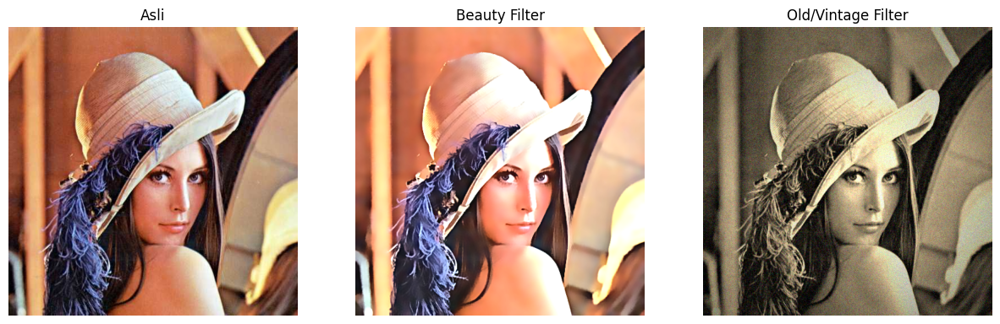

Rerata kecerahan  asli 122.2 | beauty 156.1 | vintage 107.6


In [15]:
# ===== 1. Beauty Filter =====
smooth = cv.bilateralFilter(img, d=15, sigmaColor=75, sigmaSpace=75)       # haluskan kulit
gaussian = cv.GaussianBlur(smooth, (0, 0), 3)
sharpened_b = cv.addWeighted(smooth, 1.5, gaussian, -0.5, 0)               # unsharp masking
alpha, beta = 1.2, 15                                                       # kontras, kecerahan
beauty = cv.convertScaleAbs(sharpened_b, alpha=alpha, beta=beta)

# ===== 2. Old / Vintage Filter =====
sepia_kernel = np.array([[0.272, 0.534, 0.131],
                         [0.349, 0.686, 0.168],
                         [0.393, 0.769, 0.189]])
sepia = cv.transform(img, sepia_kernel)
sepia = np.clip(sepia, 0, 255).astype(np.uint8)

rows, cols = img.shape[:2]
kernel_x = cv.getGaussianKernel(cols, cols * 0.6)
kernel_y = cv.getGaussianKernel(rows, rows * 0.6)
kernel = kernel_y * kernel_x.T
mask = kernel / kernel.max()
vignette = np.copy(sepia)
for i in range(3):
    vignette[:, :, i] = vignette[:, :, i] * mask

np.random.seed(0)
noise = np.random.normal(0, 15, vignette.shape).astype(np.int16)
old_img = np.clip(vignette.astype(np.int16) + noise, 0, 255).astype(np.uint8)

show_side_by_side([img, beauty, old_img], ['Asli', 'Beauty Filter', 'Old/Vintage Filter'])
print('Rerata kecerahan  asli %.1f | beauty %.1f | vintage %.1f' % (
    cv.cvtColor(img, cv.COLOR_BGR2GRAY).mean(), cv.cvtColor(beauty, cv.COLOR_BGR2GRAY).mean(),
    cv.cvtColor(old_img, cv.COLOR_BGR2GRAY).mean()))
HASIL['p4'] = [float(cv.cvtColor(x, cv.COLOR_BGR2GRAY).mean()) for x in (img, beauty, old_img)]

### Percobaan 5 – Filter Anime / Cartoon

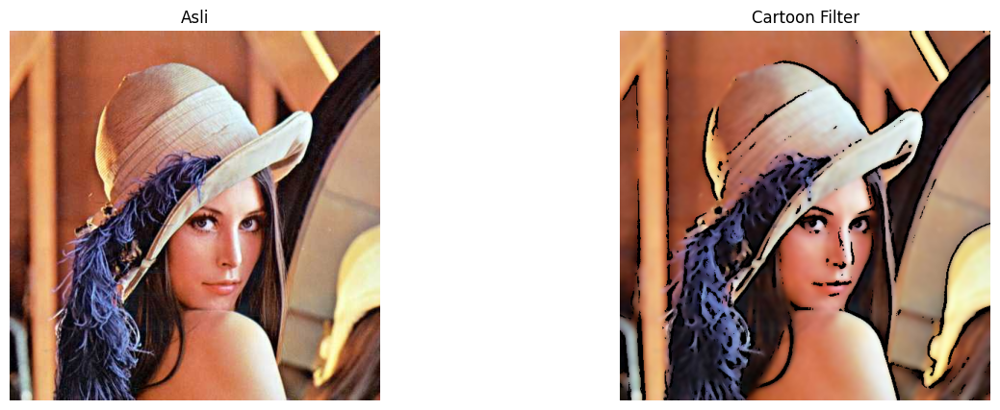

Piksel tepi (hitam) pada mask: 9.4%


In [16]:
# Step 1: edge detection (median blur dulu agar gambar lebih halus)
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
gray_blur = cv.medianBlur(gray, 7)
edges = cv.adaptiveThreshold(gray_blur, 255, cv.ADAPTIVE_THRESH_MEAN_C, cv.THRESH_BINARY, 9, 9)
# Step 2: bilateral filter untuk smoothing warna
color = cv.bilateralFilter(img, d=9, sigmaColor=200, sigmaSpace=200)
# Step 3: gabungkan (cartoonize)
cartoon = cv.bitwise_and(color, color, mask=edges)
show_side_by_side([img, cartoon], ['Asli', 'Cartoon Filter'])
print('Piksel tepi (hitam) pada mask: %.1f%%' % (100 * (edges == 0).mean()))
HASIL['p5_tepi'] = float(100 * (edges == 0).mean())

### Percobaan 6 – Filter Malam

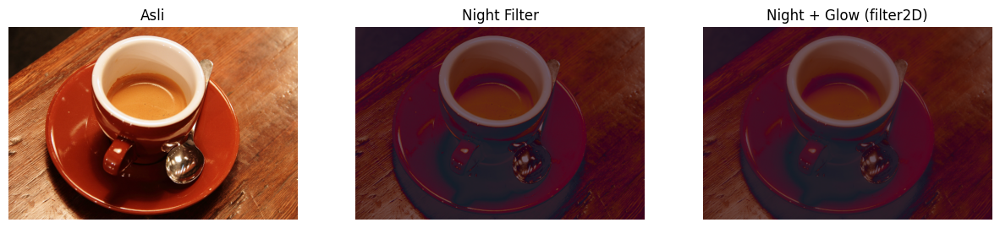

asli        rerata kecerahan 103.7
night       rerata kecerahan 38.5
night+glow  rerata kecerahan 38.5


In [17]:
img_dj = djawatan.copy()
# Step 1: gelapkan (kontras turun, kecerahan negatif)
night = cv.convertScaleAbs(img_dj, alpha=0.6, beta=-40)
# Step 2: tambah bias biru
blue_tint = np.full_like(night, (50, 0, 100))   # BGR
night = cv.addWeighted(night, 0.8, blue_tint, 0.2, 0)
# Step 3: efek glow dengan filter2D (kernel blur)
kernel = np.ones((15, 15), np.float32) / 225
glow = cv.filter2D(night, -1, kernel)
night_glow = cv.addWeighted(night, 0.7, glow, 0.3, 0)
show_side_by_side([img_dj, night, night_glow], ['Asli', 'Night Filter', 'Night + Glow (filter2D)'])
for n, c in [('asli', img_dj), ('night', night), ('night+glow', night_glow)]:
    print('%-11s rerata kecerahan %.1f' % (n, cv.cvtColor(c, cv.COLOR_BGR2GRAY).mean()))
    HASIL['p6_' + n] = float(cv.cvtColor(c, cv.COLOR_BGR2GRAY).mean())

### Percobaan 7 – Filter Pagi dan Pagi + Kabut

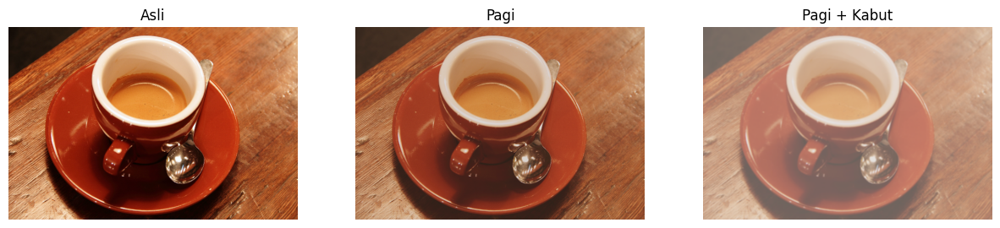

asli        rerata kecerahan 103.7 | std (kontras) 58.1
pagi        rerata kecerahan 106.9 | std (kontras) 41.9
pagi+kabut  rerata kecerahan 151.4 | std (kontras) 28.6


In [18]:
# Step 1: kurangi kontras dan cerahkan
soft = cv.convertScaleAbs(img_dj, alpha=0.9, beta=20)
# Step 2: warm tone (kemerahan / oranye)
warm_tint = np.full_like(soft, (40, 70, 120))   # BGR
pagi = cv.addWeighted(soft, 0.8, warm_tint, 0.2, 0)
# Step 3: haze (kabut tipis) dengan filter2D
kernel = cv.getGaussianKernel(3, 3)
kernel = kernel @ kernel.T
kabut = cv.filter2D(pagi, -1, kernel)
white_layer = np.full_like(pagi, 255)
kabut = cv.addWeighted(kabut, 0.7, white_layer, 0.3, 0)
show_side_by_side([img_dj, pagi, kabut], ['Asli', 'Pagi', 'Pagi + Kabut'])
for n, c in [('asli', img_dj), ('pagi', pagi), ('pagi+kabut', kabut)]:
    g = cv.cvtColor(c, cv.COLOR_BGR2GRAY)
    print('%-11s rerata kecerahan %.1f | std (kontras) %.1f' % (n, g.mean(), g.std()))
    HASIL['p7_' + n] = [float(g.mean()), float(g.std())]

## 4. Tugas Praktikum
### Tugas 1 – Mean Filter vs Median Filter pada noise Salt and Pepper

Median manual sama dengan cv.medianBlur? True


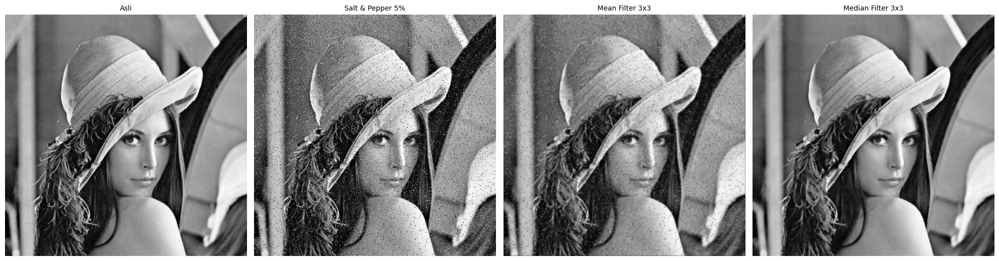

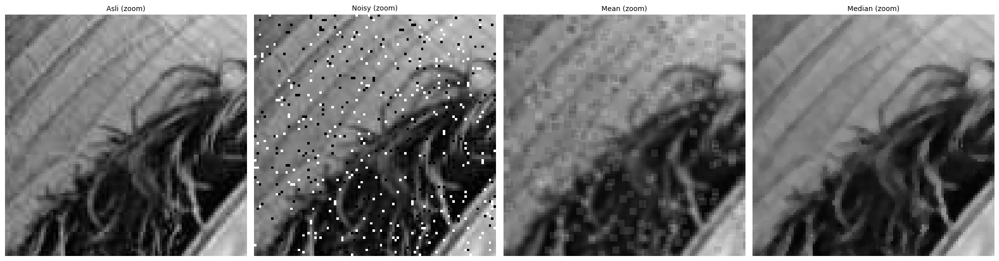

Citra              PSNR (dB)       MSE % piksel 0/255
Noisy                  18.12    1002.9           4.99
Mean 3x3               25.57     180.2           0.00
Median 3x3             33.18      31.2           0.00

Kepadatan     PSNR mean  PSNR median
1%                29.04        33.84
5%                25.57        33.18
10%               22.99        32.12
20%               19.84        28.21
30%               17.77        23.19


In [19]:
def mse(a, b): return np.mean((a.astype(np.float64) - b.astype(np.float64)) ** 2)
def psnr(a, b):
    m = mse(a, b)
    return float('inf') if m == 0 else 10 * np.log10(255.0 ** 2 / m)

def salt_pepper(gray, kepadatan=0.05, seed=42):
    """Setengah dari 'kepadatan' piksel dijadikan putih (salt), setengahnya hitam (pepper)."""
    rng = np.random.default_rng(seed)
    hasil = gray.copy()
    acak = rng.random(gray.shape)
    hasil[acak < kepadatan / 2] = 0
    hasil[(acak >= kepadatan / 2) & (acak < kepadatan)] = 255
    return hasil

def median_manual(gray, ukuran=3):
    """Median filter manual: kumpulkan semua geseran jendela lalu ambil median-nya."""
    p = ukuran // 2
    pad = np.pad(gray, p, mode='edge')
    tumpuk = [pad[i:i + gray.shape[0], j:j + gray.shape[1]] for i in range(ukuran) for j in range(ukuran)]
    return np.median(np.stack(tumpuk), axis=0).astype(np.uint8)

asli = lena_gray
noisy = salt_pepper(asli, 0.05)
mean3 = u8(np.round(convolution2d(noisy, np.ones((3, 3)) / 9, 1, 1)))
med3  = median_manual(noisy, 3)
med3_cv = cv.medianBlur(noisy, 3)
print('Median manual sama dengan cv.medianBlur?', np.array_equal(med3, med3_cv))

tampil([asli, noisy, mean3, med3], ['Asli', 'Salt & Pepper 5%', 'Mean Filter 3x3', 'Median Filter 3x3'], (20, 5.5))

# potongan diperbesar agar perbedaan terlihat
y1, y2, x1, x2 = 150, 250, 150, 250
tampil([c[y1:y2, x1:x2] for c in (asli, noisy, mean3, med3)],
       ['Asli (zoom)', 'Noisy (zoom)', 'Mean (zoom)', 'Median (zoom)'], (20, 5.5))

ekstrem = lambda c: 100 * np.mean((c == 0) | (c == 255))
print('%-18s %9s %9s %14s' % ('Citra', 'PSNR (dB)', 'MSE', '% piksel 0/255'))
for n, c in [('Noisy', noisy), ('Mean 3x3', mean3), ('Median 3x3', med3)]:
    print('%-18s %9.2f %9.1f %14.2f' % (n, psnr(asli, c), mse(asli, c), ekstrem(c)))
    HASIL['t1_' + n] = [float(psnr(asli, c)), float(mse(asli, c)), float(ekstrem(c))]
HASIL['t1_asli_ekstrem'] = float(ekstrem(asli))

# uji kepadatan noise 1% - 30%
print()
print('%-10s %12s %12s' % ('Kepadatan', 'PSNR mean', 'PSNR median'))
HASIL['t1_kepadatan'] = []
for d in [0.01, 0.05, 0.10, 0.20, 0.30]:
    nz = salt_pepper(asli, d)
    pm = psnr(asli, u8(np.round(convolution2d(nz, np.ones((3, 3)) / 9, 1, 1))))
    pd_ = psnr(asli, median_manual(nz, 3))
    print('%-10s %12.2f %12.2f' % ('%d%%' % round(d * 100), pm, pd_))
    HASIL['t1_kepadatan'].append([d, float(pm), float(pd_)])

### Tugas 2 – Memilih ukuran kernel sharpening terbaik (3×3 vs 5×5)

Jumlah koefisien 3x3 = 1.00 | 5x5 = 1.00 (=1, kecerahan rata-rata terjaga)


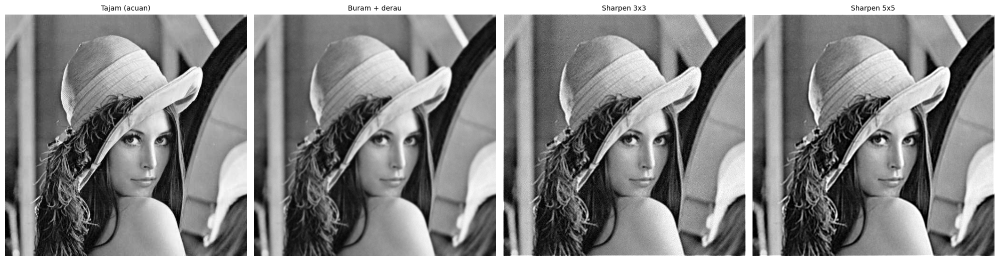

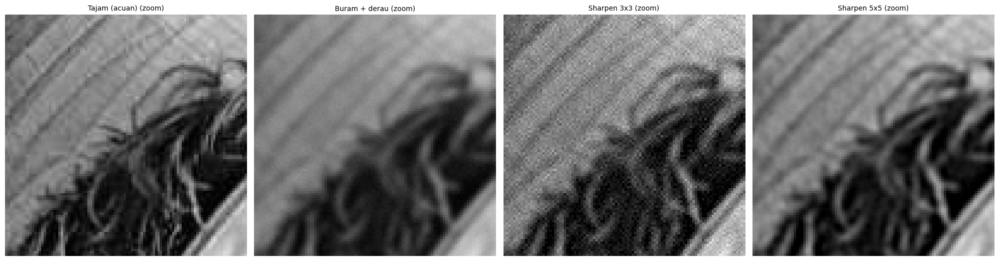

Area datar dipilih di baris 0-40, kolom 260-300
Citra              Tepi (Sobel)    Noise (std)  PSNR (dB)
Tajam (acuan)             62.60           2.93        inf
Buram + derau             45.26           3.00      28.93
Sharpen 3x3               72.86          22.38      24.87
Sharpen 5x5               67.62          13.70      28.62


In [20]:
sharp3 = np.array([[ 0, -1,  0],
                   [-1,  5, -1],
                   [ 0, -1,  0]], dtype=np.float64)
sharp5 = np.array([[-1, -1, -1, -1, -1],
                   [-1,  2,  2,  2, -1],
                   [-1,  2,  8,  2, -1],
                   [-1,  2,  2,  2, -1],
                   [-1, -1, -1, -1, -1]], dtype=np.float64) / 8
print('Jumlah koefisien 3x3 = %.2f | 5x5 = %.2f (=1, kecerahan rata-rata terjaga)' % (sharp3.sum(), sharp5.sum()))

# citra "sedikit buram": Gaussian blur dari citra tajam + derau sensor ringan agar efek noise terukur
tajam = lena_gray
buram = cv.GaussianBlur(tajam, (5, 5), 1.5).astype(np.float64)
rng = np.random.default_rng(1)
buram = u8(np.round(buram + rng.normal(0, 2, buram.shape)))

h3 = convolution2d(buram, sharp3, 1, 1)
h5 = convolution2d(buram, sharp5, 1, 2)
cit = [('Tajam (acuan)', tajam), ('Buram + derau', buram), ('Sharpen 3x3', u8(h3)), ('Sharpen 5x5', u8(h5))]
tampil([c for _, c in cit], [n for n, _ in cit], (20, 5.5))

# zoom area tepi dan area datar
ey1, ey2, ex1, ex2 = 150, 250, 150, 250
tampil([c[ey1:ey2, ex1:ex2] for _, c in cit], [n + ' (zoom)' for n, _ in cit], (20, 5.5))

# Ukuran: kejelasan tepi = rerata gradien Sobel; noise = std pada area datar; kualitas total = PSNR terhadap citra tajam
def kejelasan_tepi(c):
    gx = cv.Sobel(c, cv.CV_64F, 1, 0, ksize=3); gy = cv.Sobel(c, cv.CV_64F, 0, 1, ksize=3)
    return float(np.sqrt(gx ** 2 + gy ** 2).mean())
def std_datar(c, y1=0, y2=60, x1=0, x2=60):
    return float(c[y1:y2, x1:x2].std())
# area datar: pilih blok dengan variasi paling kecil pada citra tajam
blok = 40; terbaik = None
for y in range(0, tajam.shape[0] - blok, 20):
    for x in range(0, tajam.shape[1] - blok, 20):
        s = tajam[y:y + blok, x:x + blok].std()
        if terbaik is None or s < terbaik[0]: terbaik = (s, y, x)
_, dy, dx = terbaik
print('Area datar dipilih di baris %d-%d, kolom %d-%d' % (dy, dy + blok, dx, dx + blok))
HASIL['t2_datar'] = [dy, dy + blok, dx, dx + blok]

print('%-16s %14s %14s %10s' % ('Citra', 'Tepi (Sobel)', 'Noise (std)', 'PSNR (dB)'))
for n, c in cit:
    c8 = c if c.dtype == np.uint8 else u8(c)
    et, nd = kejelasan_tepi(c8), std_datar(c8, dy, dy + blok, dx, dx + blok)
    ps = psnr(tajam, c8) if n != 'Tajam (acuan)' else float('inf')
    print('%-16s %14.2f %14.2f %10.2f' % (n, et, nd, ps))
    HASIL['t2_' + n] = [et, nd, None if ps == float('inf') else float(ps)]

### Tugas 3 – Filter Kartun Sederhana

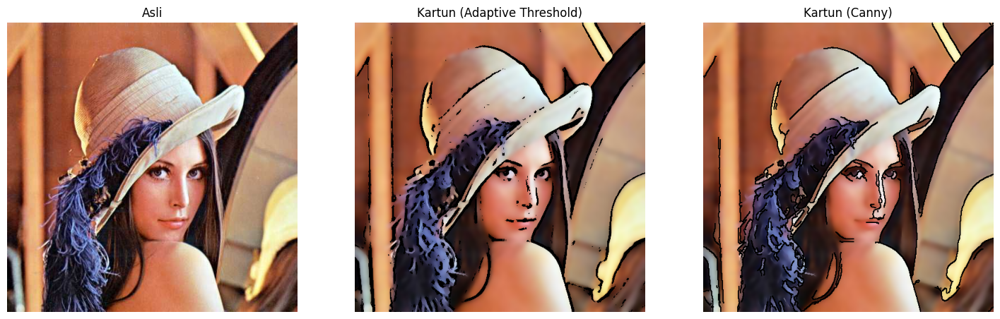

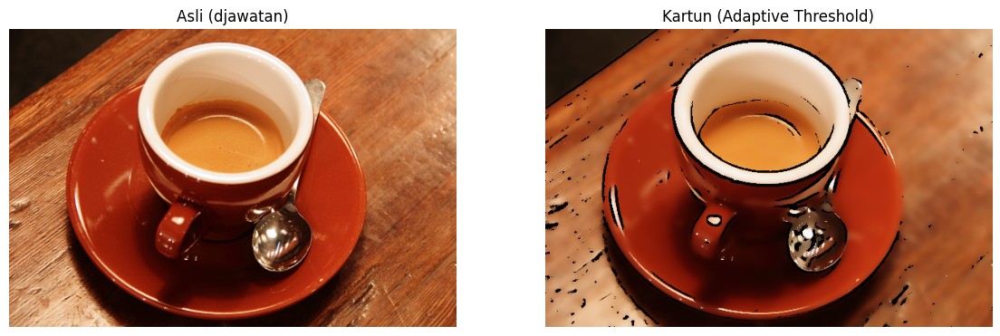

Citra                          Warna unik     Std gray
Asli                                  171         63.9
Kartun adaptif                        121         68.8
Kartun Canny                          119         68.8
Piksel garis (hitam): adaptif 9.4% | Canny 8.2%


In [21]:
def kartun(image, metode='adaptif'):
    """Filter kartun: (1) haluskan warna dengan Bilateral Filter, (2) deteksi garis tepi
    dengan Adaptive Thresholding atau Canny, (3) gabungkan dengan operasi logika AND."""
    # 1. penghalusan warna: beberapa kali bilateral agar area warna menjadi rata
    warna = image.copy()
    for _ in range(3):
        warna = cv.bilateralFilter(warna, d=9, sigmaColor=75, sigmaSpace=75)
    # 2. garis tepi
    abu = cv.medianBlur(cv.cvtColor(image, cv.COLOR_BGR2GRAY), 7)
    if metode == 'adaptif':
        garis = cv.adaptiveThreshold(abu, 255, cv.ADAPTIVE_THRESH_MEAN_C, cv.THRESH_BINARY, 9, 9)
    else:                                              # Canny: tepi putih -> dibalik agar garis hitam
        garis = cv.bitwise_not(cv.dilate(cv.Canny(abu, 80, 160), np.ones((2, 2), np.uint8)))
    # 3. gabungkan: warna hanya di mana mask garis bernilai 255, garis tepi menjadi hitam
    return cv.bitwise_and(warna, warna, mask=garis), garis

hasil_adaptif, garis_a = kartun(lena, 'adaptif')
hasil_canny, garis_c = kartun(lena, 'canny')
show_side_by_side([lena, hasil_adaptif, hasil_canny],
                  ['Asli', 'Kartun (Adaptive Threshold)', 'Kartun (Canny)'], (18, 6))

hasil_dj, _ = kartun(djawatan, 'adaptif')
show_side_by_side([djawatan, hasil_dj], ['Asli (djawatan)', 'Kartun (Adaptive Threshold)'], (14, 5))

def jumlah_warna(c, q=32):                       # jumlah warna unik setelah dikuantisasi
    return len(np.unique((c // q).reshape(-1, 3), axis=0))
print('%-28s %12s %12s' % ('Citra', 'Warna unik', 'Std gray'))
for n, c in [('Asli', lena), ('Kartun adaptif', hasil_adaptif), ('Kartun Canny', hasil_canny)]:
    print('%-28s %12d %12.1f' % (n, jumlah_warna(c), cv.cvtColor(c, cv.COLOR_BGR2GRAY).std()))
    HASIL['t3_' + n] = [jumlah_warna(c), float(cv.cvtColor(c, cv.COLOR_BGR2GRAY).std())]
HASIL['t3_garis'] = [float(100 * (garis_a == 0).mean()), float(100 * (garis_c == 0).mean())]
print('Piksel garis (hitam): adaptif %.1f%% | Canny %.1f%%' % tuple(HASIL['t3_garis']))

---
Selesai. Seluruh sel dapat dijalankan ulang dari atas (Runtime → Run all).